# 06 · Lineage specificity of p2p pdCREs (Fig 3F-L)

Compares the accessibility profiles of one-to-one p2p pdCRE pairs over 20 homologous states: their specificity (Gini
index, Fig 3F), the correlation of the two profiles (Fig 3J), and ten example pairs (Figs 3G-I, K, L).

1. **Accessibility of every locus by state**: ATAC UMIs of all namespace loci summed per state.
2. **Gini and correlation**: each of the 20 homologous states with at least 2.4M UMIs in rabbit is downsampled to 2.4M
   UMIs (seed 19); per locus, the Gini index over the states and, per pair, the correlation of log2(1 + UMIs). Pairs:
   one-to-one p2p, both pdCREs in CRECls outside the extended weak lists and the small CRECls, > 128 UMIs in both.
3. **Fig 3F** (Gini, mouse vs rabbit) and **Fig 3J** (correlation of the pairs with Gini > 0.4 in both).
4. **Figs 3G-I, K, L**: accessibility around ten example pairs, summed over five lineages.

In the paper, the example panels are recoloured and the labels of Figs 3F and 3J were set by hand.

## Setup

In [1]:
source("../R/setup.R")
source("../R/cell_types.R")
suppressPackageStartupMessages({
    library(DescTools)
    library(zoo)
})
out_dir = out_path("06_lineage_specificity")
O1 = file.path(OUT_DIR, "01_crecls")
O2 = file.path(OUT_DIR, "02_states")
O5 = file.path(OUT_DIR, "05_orthology")
states = readRDS(file.path(O2, "states.rds"))
units = fread(file.path(O1, "units.csv"))

## 1. Accessibility of every locus by state

ATAC UMIs of all 157,202 mouse and 155,012 rabbit loci, summed over the SMCs / metacells used for the CRECls (notebook
01) of each state (notebook 02), states in cell-type order.

In [2]:
mm_sup = states$mm_sup; oc_sup = states$oc_sup
mm_mclst_type = states$mm_mclst_type; oc_mclst_type = states$oc_mclst_type
rbomcs = states$rbomcs
mc_type_mm = fread(data_path("mc_type_mm_2025.csv"))
mc_type_oc = fread(data_path("metacell_types-2024-12-04.csv")) %>%
    mutate(metacell = gsub(".[0-9]+$", "", gsub("^M", "mc", metacell))) %>%
    filter(color %in% oc_type_colors) %>%
    arrange(match(color, oc_type_colors))
mm_idx2smc = setNames(mc_type_mm$smc, mc_type_mm$index)
mm_col_order = mc_type_mm %>% filter(color %in% mm_type_colors) %>% arrange(match(color, mm_type_colors)) %>% pull(cell_type) %>% unique()
oc_col_order = unique(mc_type_oc$cell_type)

mm_atac_m = as.matrix(fread(data_path("mc_atac_mat_2025.csv")) %>% column_to_rownames("mm_locid") %>% select(-chrom, -start, -end))
mm_smc_atac = t(col_group_sums(mm_atac_m[, names(mm_idx2smc)], mm_idx2smc))
oc_mc_atac = as.matrix(fread(data_path("gotg_mc_p_multi_full.csv")) %>% column_to_rownames("oc_locid"))
mm_f3 = colnames(mm_smc_atac) %in% (units %>% filter(species == "mouse", used) %>% pull(unit))
oc_f3 = colnames(oc_mc_atac) %in% (units %>% filter(species == "rabbit", used) %>% pull(unit))
mm_a_sum_by_sup_all_all = t(col_group_sums(mm_smc_atac[,mm_f3], mm_sup[colnames(mm_smc_atac)[mm_f3]]))[,order(match(mm_mclst_type, mm_col_order))]
oc_a_sum_by_sup_all_all = t(col_group_sums(oc_mc_atac[,oc_f3], oc_sup[colnames(oc_mc_atac)[oc_f3]]))[,order(match(oc_mclst_type, oc_col_order))]
rm(mm_atac_m)
fwrite(as.data.frame(mm_a_sum_by_sup_all_all) %>% rownames_to_column("mm_locid"), file.path(out_dir, "mm_a_sum_by_sup_all_all.csv"))
fwrite(as.data.frame(oc_a_sum_by_sup_all_all) %>% rownames_to_column("oc_locid"), file.path(out_dir, "oc_a_sum_by_sup_all_all.csv"))

## 2. Gini and correlation

Of the 24 homologous states, the four whose rabbit state has fewer than 2.4M UMIs (OC11, OC18, OC35, OC39) are left
out. `mm_weak_e` and `oc_weak_e` extend the weak lists with 16 mouse and 18 rabbit CRECls that notebook 03 classes as
variable, as the original analysis did (no rule was found for them).

In [3]:
mm_weak_e = c("2", "10", "16", "23", "32", "34", "37", "39", "43", "47",
"49", "52", "55", "56", "64", "66", "69", "70", "75", "76", "81",
"83", "84", "87", "94", "98")
mm_small_crecls = c("5")
oc_weak_e = c("1", "3", "4", "12", "14", "16", "17", "19", "26", "32", "34",
"42", "43", "44", "53", "67", "69", "75", "78", "79", "80", "83",
"86", "90")
oc_small_crecls = c("76", "88")

In [4]:
orth = fread(file.path(O5, "orth_full_wmode_wgotg.csv"))
mm_crecl = fread(file.path(O1, "mm_crecl.csv"))
oc_crecl = fread(file.path(O1, "oc_crecl.csv"))
mm_km = as.character(mm_crecl$kmc)
names(mm_km) = mm_crecl$locid
oc_km = as.character(oc_crecl$kmc)
names(oc_km) = oc_crecl$locid
orth$mm_km = mm_km[orth$mm_locid]
orth$oc_km = oc_km[orth$oc_locid]

gini_states = rbomcs %>% filter(!rabbit_mcc %in% c("OC11", "OC18", "OC35", "OC39"))
mm_ds = tglkmeans::downsample_matrix(mm_a_sum_by_sup_all_all[, gini_states$mouse_mcc], target_n = 2400000, seed = 19)
oc_ds = tglkmeans::downsample_matrix(oc_a_sum_by_sup_all_all[, gini_states$rabbit_mcc], target_n = 2400000, seed = 19)
mm_ds_cov = rowSums(mm_ds)
oc_ds_cov = rowSums(oc_ds)
mm_gini = apply(mm_ds,1,Gini)
oc_gini = apply(oc_ds,1,Gini)
orth_atac = orth %>% left_join(as.data.frame(mm_ds) %>% rownames_to_column("mm_locid"), by = "mm_locid") %>% left_join(as.data.frame(oc_ds) %>% rownames_to_column("oc_locid"), by = "oc_locid") %>% mutate(mm_gini = mm_gini[mm_locid], oc_gini = oc_gini[oc_locid], mm_cov=mm_ds_cov[mm_locid], oc_cov=oc_ds_cov[oc_locid])
p2p_atac = orth_atac %>% filter(!is.na(mm_km) & !mm_km %in% c(mm_weak_e, mm_small_crecls) & mm_mode=="p2p") %>%
    filter(mm_orth_tot == 1) %>% filter(oc_orth_tot == 1) %>% filter(!is.na(oc_km) & !oc_km %in% c(oc_weak_e, oc_small_crecls))
p2p_cors = tgs_cor(t(as.matrix(log2(1+(mm_ds[p2p_atac$mm_locid,])))), t(as.matrix(log2(1+(oc_ds[p2p_atac$oc_locid,])))))
p2p_atac$cor = diag(p2p_cors)
p2p_h2h = p2p_atac %>% filter(mm_cov > 128) %>% filter(oc_cov > 128)

## 3. Figs 3F and 3J

Fig 3F: Gini of the pairs in mouse (x) and rabbit (y) (`tgutil::plot_dense_scatter`). Fig 3J: correlation of the pairs
with Gini > 0.4 in both species, with the 0.2 line.

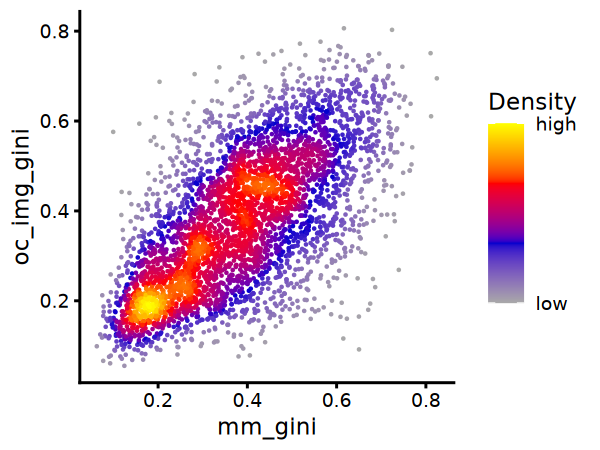

In [5]:
options(repr.plot.width = 4, repr.plot.height = 3)
local({
    mm_gini = p2p_h2h %>% pull(mm_gini)
    oc_img_gini = p2p_h2h %>% pull(oc_gini)
    plot_dense_scatter(mm_gini, oc_img_gini,size=0.05, legend = T)
})

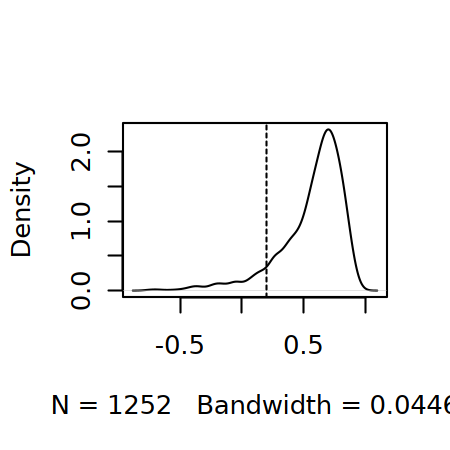

In [6]:
options(repr.plot.width = 3, repr.plot.height = 3)
plot(density(p2p_h2h %>% filter(mm_gini > 0.4) %>% filter(oc_gini > 0.4) %>% pull(cor)), main='')
abline(v=0.2, lty=2)

## 4. Figs 3G-I, K, L

The ten examples of the paper. Per example: the per-state ATAC in 20-bp bins over the locus +-750 bp, summed into five
lineages, as a running sum over 14 bins (280 bp), divided by the lineage's maximum over the ribosomal-protein TSS loci;
mouse left, rabbit right. The gene and distance in each title are the labels of the original analysis (nearest TSS of a
gene of its list, in kb); the titles are added here.

In [7]:
mm_type_key = mc_type_mm %>% select(cell_type, color) %>% distinct()
mm_code_color = mm_type_key$color
names(mm_code_color) = mm_type_key$cell_type
# state types by metacell counts (rows of mc_type_mm_smc_sup.csv)
mc_type_mm_sup = fread(file.path(O2, "mc_type_mm_smc_sup.csv"))
smc_type_mm_df = mc_type_mm_sup %>% select(smc, smc_type) %>% distinct()
smc_type_mm = smc_type_mm_df$smc_type
names(smc_type_mm) = smc_type_mm_df$smc
mm_sup_mc = mc_type_mm_sup %>% select(smc, sup) %>% tibble::deframe()
mm_mclst_types_n = table(mm_sup_mc,smc_type_mm[names(mm_sup_mc)])
mm_mclst_type_mc = colnames(mm_mclst_types_n)[apply(mm_mclst_types_n,1,which.max)]
names(mm_mclst_type_mc) = rownames(mm_mclst_types_n)
mm_mct_cols = mm_code_color[mm_mclst_type_mc]
names(mm_mct_cols) = names(mm_mclst_type_mc)
# lineages of the states
mm_full_grouping = c(
"MM1"= "exclude", "MM2"= "ecto", "MM3"= "ecto", "MM4"= "ecto", "MM6"= "ecto", "MM8"= "ecto", "MM9"= "ecto", "MM5"= "ecto",
"MM10"= "epi", "MM12"= "epi", "MM11"= "epi", "MM13"= "epi", "MM14"= "epi",
"MM17"="meso" , "MM18"="meso" , "MM19"="meso" , "MM16"="meso" , "MM20"="meso" , "MM7"= "meso", "MM22"="meso" ,
"MM21"="meso" , "MM23"="meso" , "MM25"="meso" , "MM26"="meso" ,
"MM27"="exmeso" , "MM28"="exmeso" , "MM24"="exmeso" , "MM29"="exmeso" , "MM30"="exmeso" , "MM31"="exmeso" ,
"MM32"="exmeso" , "MM33"="exmeso" , "MM34"="exmeso" ,
"MM36"= "endo", "MM15"= "endo" , "MM37"= "endo", "MM35"= "endo", "MM39"= "endo", "MM38"= "endo", "MM40"= "endo"
)
oc_full_grouping = c(
"OC1"= "ecto", "OC4"= "ecto", "OC5"= "ecto", "OC7"= "ecto", "OC8"= "ecto", "OC9"= "ecto", "OC3"= "ecto",
"OC12"="epi" , "OC2"= "epi", "OC13"="epi" , "OC10"="epi" , "OC11"="epi" , "OC14"="epi" , "OC6"= "epi",
"OC15"= "meso", "OC16"= "meso", "OC18"= "meso", "OC17"= "meso", "OC19"= "meso", "OC21"= "meso", "OC22"= "meso",
"OC23"= "meso", "OC25"= "meso", "OC26"= "meso", "OC24"= "meso", "OC27"= "meso",
"OC29"= "exmeso", "OC31"= "exmeso", "OC28"= "exmeso", "OC32"= "exmeso", "OC33"= "exmeso", "OC34"= "exmeso",
"OC20"= "exmeso", "OC30"= "exmeso", "OC35"= "exmeso",
"OC37"= "endo", "OC36"= "endo", "OC38"= "endo", "OC39"= "endo", "OC40"= "endo"
)
# the colour of a lineage is the mean RGB of its states' colours
gcols = tibble::enframe(mm_mct_cols) %>% rowwise() %>% mutate(
hex1=col2rgb(value)[1], hex2=col2rgb(value)[2], hex3=col2rgb(value)[3]
) %>% ungroup() %>% mutate(g = mm_full_grouping[name]) %>% group_by(g) %>% summarise(hex1=as.integer(mean(hex1)), hex2=as.integer(mean(hex2)), hex3=as.integer(mean(hex3))) %>% mutate(col = rgb(hex1/255, hex2/255, hex3/255)) %>% select(g, col) %>% tibble::deframe()

In [8]:
mm_prof = fread(data_path("mm_example_profiles.csv"))
oc_prof = fread(data_path("oc_example_profiles.csv"))
mm_rp = mm_prof %>% filter(set == "rp") %>% select(-set)
oc_rp = oc_prof %>% filter(set == "rp") %>% select(-set)
mm_horizon_atacs = mm_prof %>% filter(set == "example") %>% select(-set) %>% mutate(interval_length=end1-start1) %>% mutate(idx=(start-start1+140)/interval_length)
oc_horizon_atacs = oc_prof %>% filter(set == "example") %>% select(-set) %>% mutate(interval_length=end1-start1) %>% mutate(idx=(start-start1+140)/interval_length)

# per lineage, the maximum over the ribosomal-protein TSS loci of the 14-bin running sum
w_size = 14
group_rp_norm = function(rp, grouping, id) {
    mat = as.matrix(rp %>% select(-chrom, -start, -end, -chrom1, -start1, -end1, -all_of(id)))
    mat[is.na(mat)] = 0
    grouped = t(col_group_sums(mat, grouping[colnames(mat)]))
    smoothed_max = as.data.frame(grouped) %>% mutate(locid = rp[[id]]) %>% group_by(locid) %>%
        mutate(across(c(ecto, epi, meso, exmeso, endo), \(x) rollsum(x, w_size, na.rm=T, f='e'))) %>%
        summarise(across(c(ecto, epi, meso, exmeso, endo), max))
    apply(smoothed_max %>% select(-locid), 2, max)
}
mm_group_rp_norm = group_rp_norm(mm_rp, mm_full_grouping, "mm_locid")
oc_group_rp_norm = group_rp_norm(oc_rp, oc_full_grouping, "oc_locid")

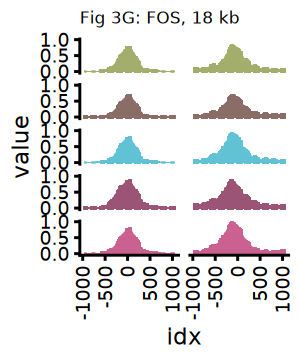

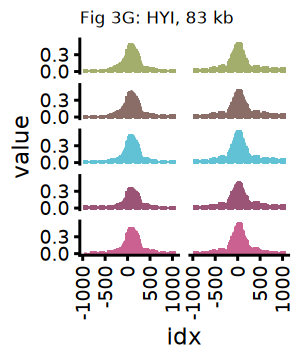

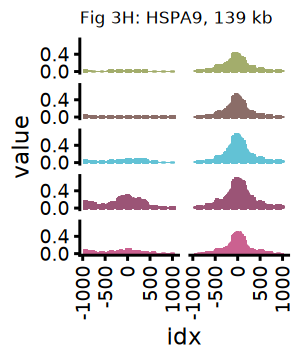

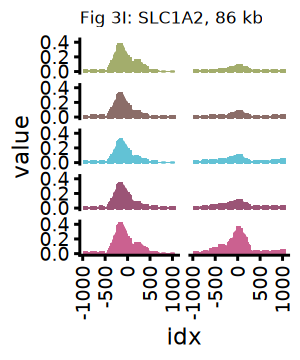

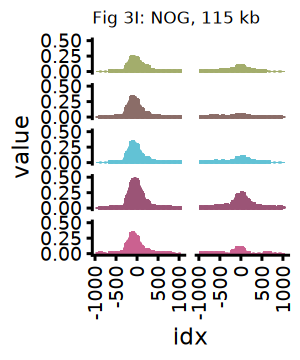

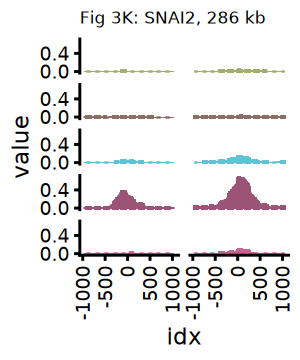

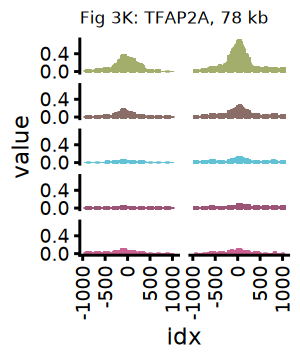

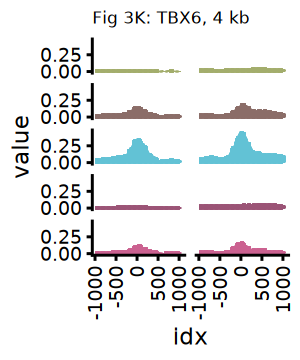

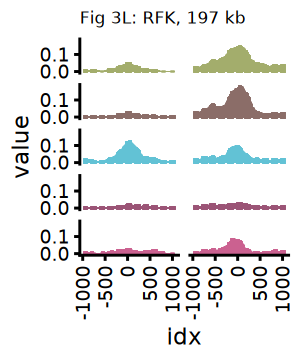

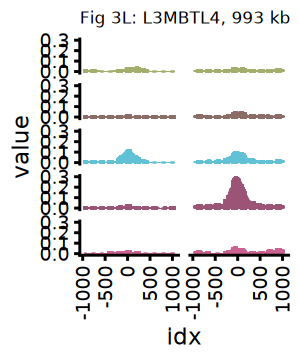

In [9]:
examples = tribble(
    ~panel, ~mm_locid,      ~oc_locid,      ~gene,     ~d,
    "G",    "mm_loc_22483", "oc_loc_54286", "FOS",     18,
    "G",    "mm_loc_69699", "oc_loc_23467", "HYI",     83,
    "H",    "mm_loc_46592", "oc_loc_56401", "HSPA9",   139,
    "I",    "mm_loc_55947", "oc_loc_7101",  "SLC1A2",  86,
    "I",    "mm_loc_16917", "oc_loc_45060", "NOG",     115,
    "K",    "mm_loc_38252", "oc_loc_58281", "SNAI2",   286,
    "K",    "mm_loc_25466", "oc_loc_17842", "TFAP2A",  78,
    "K",    "mm_loc_90155", "oc_loc_68123", "TBX6",    4,
    "L",    "mm_loc_49759", "oc_loc_2956",  "RFK",     197,
    "L",    "mm_loc_44478", "oc_loc_79782", "L3MBTL4", 993
)
options(repr.plot.width = 2, repr.plot.height = 2.4)
for (i in 1:nrow(examples)) {
mm_loc = examples[i,]$mm_locid
oc_loc = examples[i,]$oc_locid
gene = examples[i,]$gene
d = examples[i,]$d
mm_horizon_atac = mm_horizon_atacs %>% filter(mm_locid == mm_loc)
oc_horizon_atac = oc_horizon_atacs %>% filter(oc_locid == oc_loc)
mm_horizon_atac_mat = as.matrix(mm_horizon_atac %>% select(-chrom, -start, -end, -chrom1, -start1, -end1, -idx, -interval_length, -mm_locid))
oc_horizon_atac_mat = as.matrix(oc_horizon_atac %>% select(-chrom, -start, -end, -chrom1, -start1, -end1, -idx, -interval_length, -oc_locid))
mm_horizon_atac_mat[is.na(mm_horizon_atac_mat)] = 0
oc_horizon_atac_mat[is.na(oc_horizon_atac_mat)] = 0
mm_horizon_atac_mat_grouped = t(col_group_sums(mm_horizon_atac_mat, mm_full_grouping[colnames(mm_horizon_atac_mat)]))
oc_horizon_atac_mat_grouped = t(col_group_sums(oc_horizon_atac_mat, oc_full_grouping[colnames(oc_horizon_atac_mat)]))
mm_smoothed = apply(mm_horizon_atac_mat_grouped, 2, function(x) rollsum(x, w_size, na.rm=T, f='e'))
oc_smoothed = apply(oc_horizon_atac_mat_grouped, 2, function(x) rollsum(x, w_size, na.rm=T, f='e'))
mm_smoothed = t(t(mm_smoothed) / mm_group_rp_norm[colnames(mm_smoothed)])
oc_smoothed = t(t(oc_smoothed) / oc_group_rp_norm[colnames(oc_smoothed)])
mm_to_plot = as.data.frame(mm_smoothed) %>% mutate(idx = mm_horizon_atac %>% pull(idx)) %>% pivot_longer(!idx) %>% filter(name %in% c("ecto", "epi", "meso", "exmeso", "endo")) %>% mutate(name=factor(name, levels = c("ecto", "epi", "meso", "exmeso", "endo"))) %>% mutate(spec="mm")
oc_to_plot = as.data.frame(oc_smoothed) %>% mutate(idx = oc_horizon_atac %>% pull(idx)) %>% pivot_longer(!idx) %>% filter(name %in% c("ecto", "epi", "meso", "exmeso", "endo")) %>% mutate(name=factor(name, levels = c("ecto", "epi", "meso", "exmeso", "endo"))) %>% mutate(spec="oc")
mm_test = rbind(
    mm_to_plot %>% mutate(mm_name=NA, col=NA) %>% filter(!is.na(name)),
    structure(list(idx = 0, name = "guide", value = 0,
    spec = "mm", mm_name = NA, col = NA), row.names = c(NA,
-1L), class = c("tbl_df", "tbl", "data.frame"))
) %>% mutate(size=ifelse(is.na(col),-1,3)) %>% mutate(alpha=ifelse(is.na(col),0,1)) %>% mutate(pch=ifelse(is.na(col),19,21)) %>% mutate(col=ifelse(is.na(col),gcols[as.character(name)],col))
oc_test = rbind(
    oc_to_plot %>% mutate(oc_name=NA, col=NA) %>% filter(!is.na(name)),
    structure(list(idx = 0, name = "guide", value = 0,
    spec = "oc", oc_name = NA, col = NA), row.names = c(NA,
-1L), class = c("tbl_df", "tbl", "data.frame"))
) %>% mutate(size=ifelse(is.na(col),-1,3)) %>% mutate(alpha=ifelse(is.na(col),0,0)) %>% mutate(pch=ifelse(is.na(col),19,21)) %>% mutate(col=ifelse(is.na(col),gcols[as.character(name)],col))
mm_plot = rbind(
    mm_test  %>% select(-mm_name),
    oc_test %>% select(-oc_name)
) %>%
    filter(name != "guide") %>%
    mutate(idx = 2000 * idx - 1100) %>%
    ggplot() +
    geom_point(aes(idx, value, fill = col, size = size, pch = pch, alpha = alpha)) +
    geom_col(aes(x = idx, y = value, color = col, fill = col)) +
    scale_alpha_identity() +
    scale_shape_identity() +
    scale_fill_identity() +
    scale_color_identity() +
    scale_y_continuous(n.breaks = 3) +
    facet_grid(name ~ spec) +
    theme_classic() +
    theme(legend.position = "none") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1)) +
    theme(strip.text = element_blank())
print(mm_plot + labs(title = sprintf("Fig 3%s: %s, %d kb", examples[i,]$panel, gene, d)) + theme(plot.title = element_text(size = 8)))
}